<a href="https://colab.research.google.com/github/arielsharonferdinandus/Telco_Customer_Churn_Prediction/blob/Business-understanding-and-data-diagnosis/Telco_Churn_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telco Customer Churn Prediction (PA-1A)

**Dataset:** Telco Customer Churn (IBM, via Kaggle) — `1A_telco_customer_churn.csv`
**Sumber:** https://github.com/arielsharonferdinandus/Telco_Customer_Churn_Prediction/blob/main/data/1A_telco_customer_churn.csv

Notebook ini disusun bertahap per *phase*:

| Phase | Isi |
|---|---|
| **1** | Task 1 — Business Understanding, Data Quality Check, EDA |
| 2 | Task 2 — Data Preparation & Feature Engineering |
| 3 | Task 3 — Modeling, Comparison & Optimization |
| 4 | Task 4 — Evaluation, Interpretation & Business Recommendation |

In [1]:
import warnings, os, urllib.request
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42          # dipakai konsisten di seluruh notebook
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.spines.top': False, 'axes.spines.right': False})
COL = {'No': '#4C78A8', 'Yes': '#E4572E'}   # warna konsisten: No = biru, Yes (churn) = oranye-merah

---
# TASK 1 — Business Understanding & Data Diagnosis

## 1.1 Business Understanding

### Latar belakang
Industri telekomunikasi sangat kompetitif dan pelanggan mudah berpindah operator. Mendapatkan pelanggan baru umumnya jauh lebih mahal daripada mempertahankan pelanggan yang sudah ada, sehingga **churn** (pelanggan berhenti berlangganan) langsung menggerus pendapatan berulang. Pada dataset ini sekitar **26,5%** pelanggan churn — lebih dari satu dari empat pelanggan. Tim retensi memiliki sumber daya terbatas (anggaran, jumlah agen, penawaran diskon), sehingga tidak mungkin menghubungi semua pelanggan.

### Problem statement
Perusahaan telekomunikasi kehilangan sekitar 26,5% pelanggannya akibat churn, namun program retensi hanya dapat menjangkau sebagian kecil pelanggan karena keterbatasan anggaran dan kapasitas tim, sehingga tanpa kemampuan memprediksi siapa yang berisiko tinggi, upaya retensi cenderung dilakukan secara acak dan tidak efisien. Proyek ini membangun model klasifikasi biner yang memprediksi kemungkinan churn setiap pelanggan berdasarkan profil demografi, layanan yang digunakan, kontrak, dan pola penagihan, lalu mengurutkan pelanggan berdasarkan risiko agar tim retensi memprioritaskan pelanggan yang paling mungkin churn dan paling bernilai untuk dipertahankan.

### Tujuan penggunaan Machine Learning
1. **Memprioritaskan** pelanggan berisiko tinggi (ranking berbasis probabilitas churn) untuk program retensi.
2. **Meningkatkan efisiensi biaya** — jumlah pelanggan yang dihubungi sama, tetapi proporsi yang benar-benar akan churn (precision) lebih tinggi dibanding pemilihan acak.
3. **Mengidentifikasi pendorong churn** (kontrak, layanan, pembayaran, dll.) sebagai dasar desain program retensi.

### Target prediksi dan definisi kelas
| Kelas | Nilai `Churn` | Label model | Arti |
|---|---|---|---|
| Positif | `Yes` | 1 | Pelanggan berhenti berlangganan |
| Negatif | `No` | 0 | Pelanggan tetap berlangganan |

Masalah: **binary classification** dengan kelas positif (churn) sebagai minoritas (~26,5%).

### Metrik evaluasi model dan alasan pemilihan
| Metrik | Alasan pemilihan berdasarkan tujuan bisnis |
|---|---|
| **ROC-AUC** | Mengukur kemampuan model *meranking* pelanggan churn di atas non-churn pada semua threshold. Cocok karena output model dipakai sebagai skor prioritas, dan tidak bergantung pada satu threshold. |
| **PR-AUC** | Lebih sensitif terhadap kelas minoritas dibanding ROC-AUC saat data tidak seimbang. Baseline PR-AUC ≈ proporsi churn (0,265), sehingga mudah melihat nilai tambah model. |
| **Precision** | Dari pelanggan yang dihubungi, berapa persen benar-benar akan churn. Precision rendah = biaya retensi terbuang ke pelanggan yang sebenarnya akan tetap bertahan (dan diskon yang tidak perlu). |
| **Recall** | Dari seluruh pelanggan churn, berapa persen berhasil ditangkap. Recall rendah = banyak pendapatan hilang tanpa sempat ditangani. |
| **F1-Score** | Rata-rata harmonik precision dan recall; ringkasan tunggal untuk keseimbangan keduanya pada threshold tertentu. |
| **Confusion Matrix** | Menunjukkan jumlah TP, FP, FN, TN sehingga kesalahan dapat diterjemahkan langsung ke biaya (FP = biaya kampanye terbuang; FN = pelanggan churn terlewat). |

> **Catatan:** *Accuracy* tidak dijadikan metrik utama. Model yang selalu menebak "tidak churn" sudah mencapai akurasi ≈ 73,5% tanpa menangkap satu pun pelanggan churn.

### Metrik bisnis keberhasilan program retensi
| Metrik bisnis | Definisi | Alasan |
|---|---|---|
| **Churn rate** | Churn / total pelanggan | Indikator utama kesehatan basis pelanggan; target program adalah menurunkannya. |
| **Retention rate** | 1 − churn rate | Sisi positif dari churn rate; mudah dikomunikasikan ke manajemen. |
| **Expected saved revenue** | Pelanggan berhasil dipertahankan × MonthlyCharges × periode proyeksi | Menerjemahkan hasil model menjadi rupiah/dolar yang diselamatkan. |
| **Retention campaign conversion rate** | % pelanggan yang dikontak dan akhirnya bertahan | Mengukur efektivitas aksi retensi (diasumsikan, bukan diprediksi model). |
| **Lift @ top-k%** | Churn rate pada k% skor tertinggi ÷ churn rate keseluruhan | Mengukur seberapa lebih baik model dibanding pemilihan acak, sesuai kapasitas tim retensi (mis. top 10%/20%). |

## 1.2 Data Quality Check
Memuat data, lalu memeriksa tujuh aspek: missing values, duplikasi, tipe data, outlier, class imbalance, nilai tidak konsisten/tidak valid, serta distribusi kategori.

In [2]:
# Muat data dari folder lokal; jika belum ada, unduh dari GitHub (sumber yang ditentukan)
DATA_PATH = 'data/1A_telco_customer_churn.csv'
GITHUB_RAW = 'https://raw.githubusercontent.com/arielsharonferdinandus/Telco_Customer_Churn_Prediction/main/data/1A_telco_customer_churn.csv'
if not os.path.exists(DATA_PATH):
    os.makedirs('data', exist_ok=True)
    urllib.request.urlretrieve(GITHUB_RAW, DATA_PATH)

df_raw = pd.read_csv(DATA_PATH)
print('Shape:', df_raw.shape)
df_raw.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# 1) Missing values (NaN) & 3) tipe data
info = pd.DataFrame({'dtype': df_raw.dtypes.astype(str), 'n_missing': df_raw.isna().sum(), 'n_unique': df_raw.nunique()})
info

,dtype,n_missing,n_unique
customerID,object,0,7043
gender,object,0,2
SeniorCitizen,int64,0,2
Partner,object,0,2
Dependents,object,0,2
tenure,int64,0,73
PhoneService,object,0,2
MultipleLines,object,0,3
InternetService,object,0,3
OnlineSecurity,object,0,3


In [4]:
# 2) Duplikasi
print('Baris duplikat penuh      :', df_raw.duplicated().sum())
print('customerID duplikat       :', df_raw['customerID'].duplicated().sum())

# 3) / 6) TotalCharges bertipe string -> cari nilai yang tidak bisa dikonversi ke angka
tc_num = pd.to_numeric(df_raw['TotalCharges'], errors='coerce')
bad = df_raw[tc_num.isna()]
print('\nTotalCharges tidak numerik:', len(bad), 'baris; nilai asli unik =', bad['TotalCharges'].map(repr).unique())
bad[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Baris duplikat penuh      : 0
customerID duplikat       : 0

TotalCharges tidak numerik: 11 baris; nilai asli unik = ["' '"]


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [5]:
# 6) Konsistensi logika antar kolom
chk = {}
chk['tenure = 0 (pelanggan baru)']                     = int((df_raw.tenure == 0).sum())
chk['tenure = 0 dan TotalCharges kosong']              = int(((df_raw.tenure == 0) & tc_num.isna()).sum())
chk['PhoneService=No tapi MultipleLines != "No phone service"'] = int(((df_raw.PhoneService == 'No') & (df_raw.MultipleLines != 'No phone service')).sum())
net_cols = ['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
chk['InternetService=No tapi layanan internet != "No internet service"'] = int(((df_raw.InternetService == 'No') & (df_raw[net_cols] != 'No internet service').any(axis=1)).sum())
chk['MonthlyCharges <= 0'] = int((df_raw.MonthlyCharges <= 0).sum())
chk['tenure < 0 atau > 72'] = int(((df_raw.tenure < 0) | (df_raw.tenure > 72)).sum())
chk['SeniorCitizen di luar {0,1}'] = int((~df_raw.SeniorCitizen.isin([0, 1])).sum())
# Rasio TotalCharges terhadap tenure*MonthlyCharges (wajar jika dekat 1)
ratio = (tc_num / (df_raw.tenure * df_raw.MonthlyCharges)).replace([np.inf, -np.inf], np.nan)
chk['TotalCharges menyimpang >50% dari tenure×MonthlyCharges'] = int((((ratio - 1).abs()) > 0.5).sum())
pd.Series(chk, name='jumlah baris').to_frame()

,jumlah baris
tenure = 0 (pelanggan baru),11
tenure = 0 dan TotalCharges kosong,11
"PhoneService=No tapi MultipleLines != ""No phone service""",0
"InternetService=No tapi layanan internet != ""No internet service""",0
MonthlyCharges <= 0,0
tenure < 0 atau > 72,0
"SeniorCitizen di luar {0,1}",0
TotalCharges menyimpang >50% dari tenure×MonthlyCharges,2


In [6]:
# 4) Outlier fitur numerik (aturan IQR 1.5x) — hanya dideteksi, keputusan penanganan di Task 2
num_cols = ['tenure', 'MonthlyCharges']
df_chk = df_raw.assign(TotalCharges=tc_num)
rows = []
for c in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    s = df_chk[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    rows.append({'fitur': c, 'min': s.min(), 'Q1': q1, 'median': s.median(), 'Q3': q3, 'max': s.max(),
                 'batas bawah': lo, 'batas atas': hi, 'n_outlier': int(((s < lo) | (s > hi)).sum()),
                 'skewness': round(s.skew(), 2)})
pd.DataFrame(rows).round(2)

,fitur,min,Q1,median,Q3,max,batas bawah,batas atas,n_outlier,skewness
0,tenure,0.00,9.00,29.00,55.00,72.00,-60.00,124.00,0,0.24
1,MonthlyCharges,18.25,35.50,70.35,89.85,118.75,-46.02,171.38,0,-0.22
2,TotalCharges,18.80,401.45,1397.48,3794.74,8684.80,-4688.48,8884.67,0,0.96


In [7]:
# 5) Class imbalance
vc = df_raw['Churn'].value_counts()
pd.DataFrame({'jumlah': vc, 'proporsi (%)': (vc / len(df_raw) * 100).round(2)})

,jumlah,proporsi (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


In [8]:
# 7) Distribusi kategori dan nilai unik
cat_cols = [c for c in df_raw.columns if df_raw[c].dtype == 'object' or str(df_raw[c].dtype).startswith('str')]
cat_cols = [c for c in cat_cols if c not in ('customerID', 'TotalCharges')]
for c in cat_cols:
    vc = df_raw[c].value_counts()
    print(f'{c:18s} ({len(vc)} nilai): ' + ' | '.join(f'{k}: {v}' for k, v in vc.items()))
print('\nSeniorCitizen (numerik 0/1):', df_raw.SeniorCitizen.value_counts().to_dict())

gender             (2 nilai): Male: 3555 | Female: 3488
Partner            (2 nilai): No: 3641 | Yes: 3402
Dependents         (2 nilai): No: 4933 | Yes: 2110
PhoneService       (2 nilai): Yes: 6361 | No: 682
MultipleLines      (3 nilai): No: 3390 | Yes: 2971 | No phone service: 682
InternetService    (3 nilai): Fiber optic: 3096 | DSL: 2421 | No: 1526
OnlineSecurity     (3 nilai): No: 3498 | Yes: 2019 | No internet service: 1526
OnlineBackup       (3 nilai): No: 3088 | Yes: 2429 | No internet service: 1526
DeviceProtection   (3 nilai): No: 3095 | Yes: 2422 | No internet service: 1526
TechSupport        (3 nilai): No: 3473 | Yes: 2044 | No internet service: 1526
StreamingTV        (3 nilai): No: 2810 | Yes: 2707 | No internet service: 1526
StreamingMovies    (3 nilai): No: 2785 | Yes: 2732 | No internet service: 1526
Contract           (3 nilai): Month-to-month: 3875 | Two year: 1695 | One year: 1473
PaperlessBilling   (2 nilai): Yes: 4171 | No: 2872
PaymentMethod      (4 nilai): Electr

### Tabel Data Quality

| Nama pemeriksaan | Hasil pemeriksaan | Temuan | Tindakan yang diperlukan |
|---|---|---|---|
| **Missing values** (NaN) | 0 NaN di semua 21 kolom | Tidak ada NaN eksplisit, **tetapi** `TotalCharges` memuat **11 baris berisi string kosong/spasi** (missing tersembunyi). | Konversi `TotalCharges` ke numerik; kosong menjadi NaN, lalu diimputasi (lihat temuan konsistensi). |
| **Duplicate records** | 0 baris duplikat penuh; 0 `customerID` duplikat | Tidak ada duplikasi; setiap `customerID` unik. | Tidak ada penghapusan. `customerID` dibuang dari fitur karena hanya identifier. |
| **Data types & format** | `TotalCharges` bertipe string (object); `SeniorCitizen` int 0/1; 17 kolom kategorikal berupa string | `TotalCharges` seharusnya numerik. `SeniorCitizen` bersifat biner kategorikal tetapi sudah 0/1. Target `Churn` Yes/No. | Cast `TotalCharges` → float; encode `Churn` → 0/1; kategori di-one-hot encode di Task 2. |
| **Outlier numerik** (IQR 1.5×) | `tenure`: 0, `MonthlyCharges`: 0, `TotalCharges`: 0 outlier | Tidak ada outlier IQR; rentang nilai masuk akal (tenure 0–72 bulan, MonthlyCharges 18,25–118,75). `TotalCharges` miring ke kanan (wajar: akumulasi biaya). | Tidak ada penghapusan. Skewness `TotalCharges` ditangani lewat scaling/model tree-based. |
| **Class imbalance** | No = 5.174 (73,46%); Yes = 1.869 (26,54%) | Imbalance moderat (rasio ≈ 2,8 : 1). Akurasi menyesatkan. | Stratified split; `class_weight='balanced'` + threshold tuning di Task 3; metrik utama PR-AUC/Recall/Precision. |
| **Nilai tidak konsisten / tidak valid** | 11 baris `tenure=0` dengan `TotalCharges` kosong; 682 baris `PhoneService=No` memiliki `MultipleLines="No phone service"`; 1.526 baris `InternetService=No` memiliki 6 kolom layanan = `"No internet service"` | Baris `tenure=0` adalah pelanggan baru yang **belum ditagih** (semuanya `Churn=No`) → `TotalCharges` kosong secara logis bernilai 0. Selain itu, 2 baris memiliki `TotalCharges` menyimpang >50% dari tenure × MonthlyCharges (wajar akibat perubahan paket selama berlangganan; dipertahankan). Label "No phone service"/"No internet service" bukan error, melainkan kategori turunan yang redundan dengan `PhoneService`/`InternetService`. | Imputasi `TotalCharges` = 0 untuk `tenure=0`. Label turunan di-normalisasi menjadi "No" untuk fitur layanan tambahan (informasi tetap tersimpan di `PhoneService`/`InternetService`) agar `ServiceCount` bermakna. |
| **Distribusi kategori & nilai unik** | `gender` 2, `Contract` 3, `InternetService` 3, `PaymentMethod` 4, kolom layanan 3 nilai | Kardinalitas rendah — aman untuk one-hot encoding. Tidak ada typo atau variasi penulisan. | One-hot encoding (`drop='first'` atau `handle_unknown='ignore'`) di dalam Pipeline. |

## 1.3 Exploratory Data Analysis (EDA)
Untuk EDA, tipe data dibenahi secara minimal (`TotalCharges` → numerik, `Churn` → 0/1) hanya agar dapat divisualisasikan. **Seluruh keputusan cleaning resmi didokumentasikan di Task 2.**

In [9]:
df = df_raw.copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['ChurnFlag'] = (df['Churn'] == 'Yes').astype(int)
overall = df['ChurnFlag'].mean()
print(f'Churn rate keseluruhan: {overall:.2%}')

def churn_table(col, bins=None, labels=None):
    s = pd.cut(df[col], bins=bins, labels=labels) if bins is not None else df[col]
    t = df.groupby(s, observed=True)['ChurnFlag'].agg(churn_rate='mean', n='size').reset_index()
    t['churn_rate'] *= 100
    return t

def annotate_bars(ax, fmt='{:.1f}%'):
    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            ax.annotate(fmt.format(h), (p.get_x() + p.get_width()/2, h), ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

Churn rate keseluruhan: 26.54%


### Visualisasi 1 — Distribusi target Churn

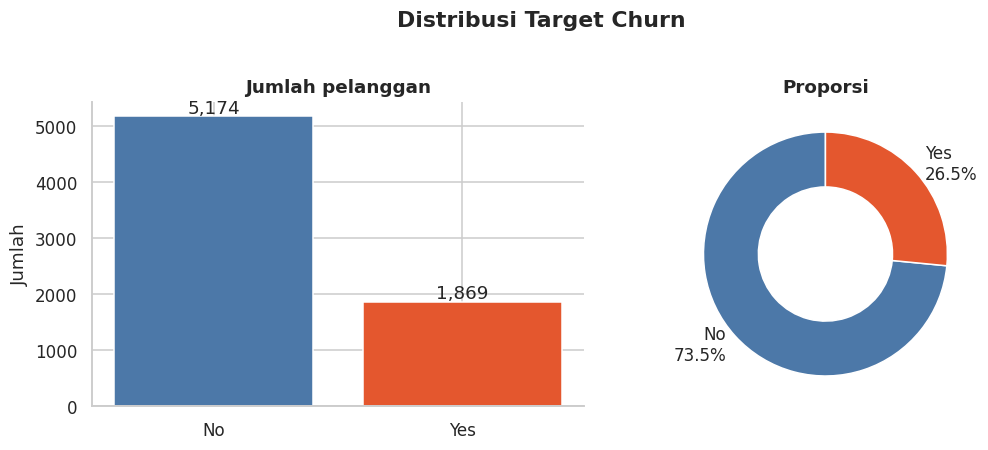

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
vc = df['Churn'].value_counts().reindex(['No', 'Yes'])
ax[0].bar(vc.index, vc.values, color=[COL['No'], COL['Yes']])
for i, v in enumerate(vc.values): ax[0].text(i, v + 60, f'{v:,}', ha='center')
ax[0].set_title('Jumlah pelanggan'); ax[0].set_ylabel('Jumlah')
ax[1].pie(vc.values, labels=[f'{k}\n{v/len(df):.1%}' for k, v in vc.items()], colors=[COL['No'], COL['Yes']], startangle=90, wedgeprops={'width': .45})
ax[1].set_title('Proporsi')
plt.suptitle('Distribusi Target Churn', y=1.02, fontweight='bold'); plt.tight_layout(); plt.show()

**Insight 1 — Distribusi target**
- Dari 7.043 pelanggan, **1.869 (26,5%) churn** dan 5.174 (73,5%) bertahan → imbalance moderat (≈ 2,8 : 1).
- **Implikasi bisnis:** hampir 1 dari 4 pelanggan hilang. Tebakan "tidak ada yang churn" akurat 73,5% tetapi tidak berguna, jadi evaluasi harus memakai PR-AUC, Recall, dan Precision, bukan akurasi.
- **Implikasi teknis:** gunakan stratified split dan penanganan imbalance (class weight, threshold tuning). Churn rate 26,5% juga menjadi *baseline* untuk menghitung lift.

### Visualisasi 2 — Churn berdasarkan Contract

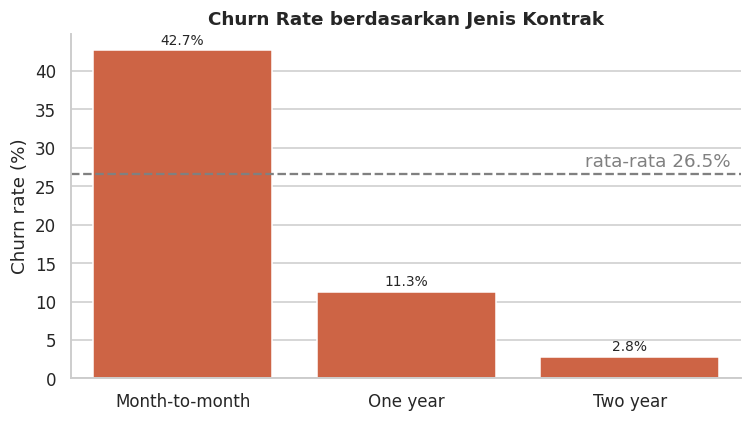

,churn_rate,n
Contract,,
Month-to-month,42.7,3875
One year,11.3,1473
Two year,2.8,1695


In [11]:
t = churn_table('Contract'); order = ['Month-to-month', 'One year', 'Two year']
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=t, x='Contract', y='churn_rate', order=order, color=COL['Yes'], ax=ax)
ax.axhline(overall*100, ls='--', c='grey'); ax.text(2.45, overall*100 + 1, f'rata-rata {overall:.1%}', ha='right', color='grey')
annotate_bars(ax); ax.set_ylabel('Churn rate (%)'); ax.set_title('Churn Rate berdasarkan Jenis Kontrak'); ax.set_xlabel('')
plt.tight_layout(); plt.show()
t.set_index('Contract').loc[order].round(1)

**Insight 2 — Contract**
- Churn rate **Month-to-month 42,7%**, One year 11,3%, Two year **2,8%** — selisih ±15× antara kontrak bulanan dan 2 tahun.
- Kontrak bulanan mencakup 3.875 pelanggan (55% basis) dan menyumbang mayoritas churn karena tidak ada hambatan untuk pindah.
- **Implikasi bisnis:** migrasi pelanggan bulanan ke kontrak 1–2 tahun (insentif diskon, bundling perangkat) adalah tuas retensi paling kuat. Perlu diingat bahwa ini asosiasi; pelanggan yang sudah loyal mungkin lebih mudah mengambil kontrak panjang.

### Visualisasi 3 — Churn berdasarkan Tenure

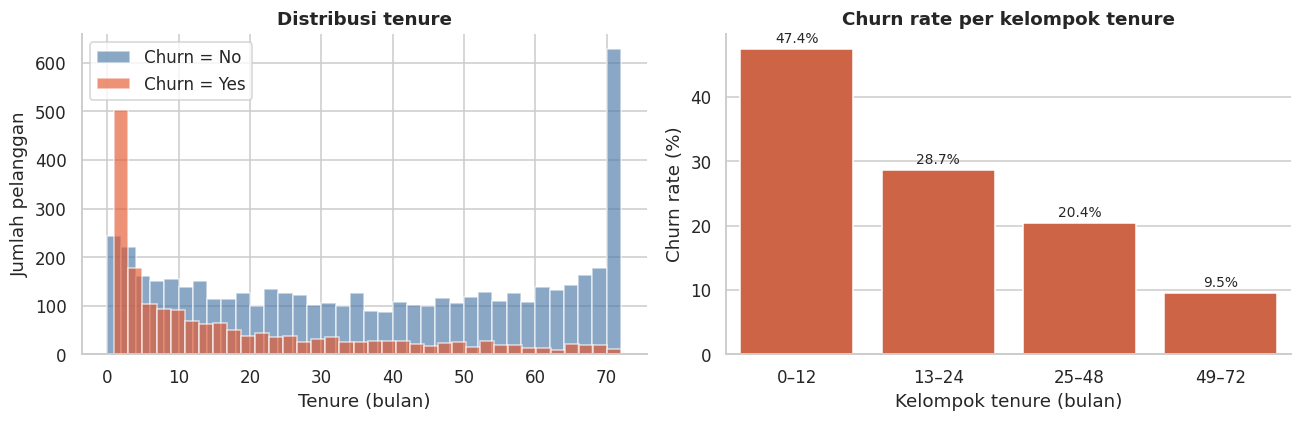

Churn                    No   Yes
median tenure (bulan)  38.0  10.0


,tenure,churn_rate,n
0,0–12,47.4,2186
1,13–24,28.7,1024
2,25–48,20.4,1594
3,49–72,9.5,2239


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k in ['No', 'Yes']:
    ax[0].hist(df.loc[df.Churn == k, 'tenure'], bins=36, alpha=.65, color=COL[k], label=f'Churn = {k}')
ax[0].set_xlabel('Tenure (bulan)'); ax[0].set_ylabel('Jumlah pelanggan'); ax[0].legend(); ax[0].set_title('Distribusi tenure')

bins = [-1, 12, 24, 48, 72]; labels = ['0–12', '13–24', '25–48', '49–72']
t = churn_table('tenure', bins, labels)
sns.barplot(data=t, x='tenure', y='churn_rate', color=COL['Yes'], ax=ax[1]); annotate_bars(ax[1])
ax[1].set_xlabel('Kelompok tenure (bulan)'); ax[1].set_ylabel('Churn rate (%)'); ax[1].set_title('Churn rate per kelompok tenure')
plt.tight_layout(); plt.show()
print(df.groupby('Churn')['tenure'].median().rename('median tenure (bulan)').to_frame().T)
t.round(1)

**Insight 3 — Tenure**
- Median tenure pelanggan churn hanya **10 bulan** vs **38 bulan** pada pelanggan bertahan.
- Churn rate turun tajam seiring tenure: **47,4%** (0–12 bln) → 28,7% → 20,4% → **9,5%** (49–72 bln).
- Pelanggan di tahun pertama (2.186 orang, 31% basis) adalah segmen paling rapuh.
- **Implikasi bisnis:** program *onboarding* dan retensi dini (check-in 30/60/90 hari, penawaran di bulan 3–6) paling berdampak. Tenure akan menjadi fitur prediktor yang kuat.

### Visualisasi 4 — Churn berdasarkan MonthlyCharges

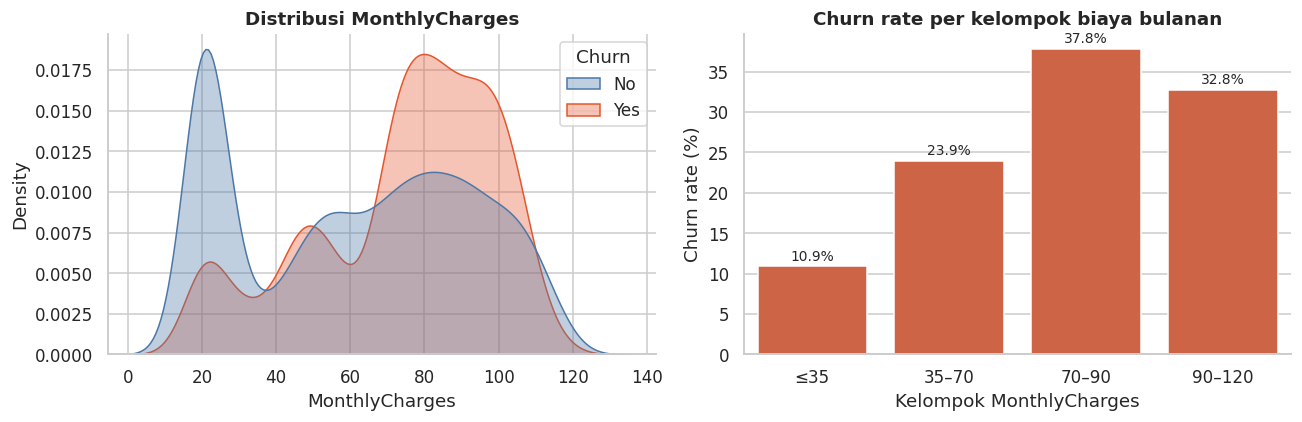

Churn                     No    Yes
median MonthlyCharges  64.43  79.65


,MonthlyCharges,churn_rate,n
0,≤35,10.9,1735
1,35–70,23.9,1725
2,70–90,37.8,1844
3,90–120,32.8,1739


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', palette=COL, common_norm=False, fill=True, alpha=.35, ax=ax[0], hue_order=['No', 'Yes'])
ax[0].set_title('Distribusi MonthlyCharges'); ax[0].set_xlabel('MonthlyCharges')
bins = [0, 35, 70, 90, 120]; labels = ['≤35', '35–70', '70–90', '90–120']
t = churn_table('MonthlyCharges', bins, labels)
sns.barplot(data=t, x='MonthlyCharges', y='churn_rate', color=COL['Yes'], ax=ax[1]); annotate_bars(ax[1])
ax[1].set_xlabel('Kelompok MonthlyCharges'); ax[1].set_ylabel('Churn rate (%)'); ax[1].set_title('Churn rate per kelompok biaya bulanan')
plt.tight_layout(); plt.show()
print(df.groupby('Churn')['MonthlyCharges'].median().rename('median MonthlyCharges').to_frame().T.round(2))
t.round(1)

**Insight 4 — MonthlyCharges**
- Median biaya bulanan pelanggan churn **79,65** vs **64,43** pada pelanggan bertahan.
- Churn rate terendah pada biaya rendah (≤35: **10,9%**) dan puncaknya pada kelompok **70–90 (37,8%)**; kelompok 90–120 sedikit lebih rendah (32,8%) — hubungan tidak sepenuhnya linear.
- Pelanggan berbiaya rendah umumnya hanya berlangganan layanan telepon dasar (tanpa internet) sehingga lebih "lengket".
- **Implikasi bisnis:** pelanggan bertagihan tinggi sekaligus berisiko tinggi = pendapatan paling terancam. Mereka layak diprioritaskan dalam program retensi (paket value, bukan sekadar diskon). Biaya bulanan perlu dikombinasikan dengan fitur lain (jenis layanan, kontrak).

### Visualisasi 5 — Churn berdasarkan InternetService

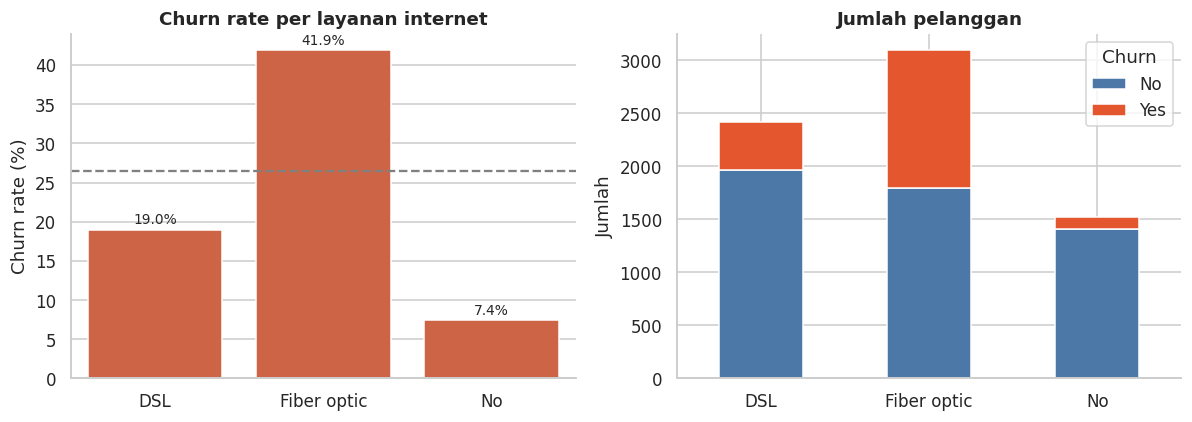

InternetService            DSL  Fiber optic     No
rata-rata MonthlyCharges  58.1         91.5  21.08


,churn_rate,n
InternetService,,
DSL,19.0,2421
Fiber optic,41.9,3096
No,7.4,1526


In [14]:
t = churn_table('InternetService'); order = ['DSL', 'Fiber optic', 'No']
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=t, x='InternetService', y='churn_rate', order=order, color=COL['Yes'], ax=ax[0]); annotate_bars(ax[0])
ax[0].axhline(overall*100, ls='--', c='grey'); ax[0].set_ylabel('Churn rate (%)'); ax[0].set_title('Churn rate per layanan internet'); ax[0].set_xlabel('')
ct = pd.crosstab(df['InternetService'], df['Churn']).reindex(order)
ct.plot(kind='bar', stacked=True, color=[COL['No'], COL['Yes']], ax=ax[1]); ax[1].set_title('Jumlah pelanggan'); ax[1].set_xlabel(''); ax[1].set_ylabel('Jumlah'); plt.setp(ax[1].get_xticklabels(), rotation=0)
plt.tight_layout(); plt.show()
print(df.groupby('InternetService')['MonthlyCharges'].mean().round(2).rename('rata-rata MonthlyCharges').to_frame().T)
t.set_index('InternetService').loc[order].round(1)

**Insight 5 — InternetService**
- Pelanggan **Fiber optic** churn **41,9%**, hampir 2,2× DSL (**19,0%**), dan jauh di atas non-internet (**7,4%**).
- Fiber adalah segmen terbesar (3.096 pelanggan) dengan tagihan tertinggi — sehingga paling banyak berkontribusi pada hilangnya pendapatan.
- **Implikasi bisnis:** investigasi kualitas layanan fiber (stabilitas, harga vs kompetitor, dukungan teknis). Mekanisme pasti tidak dapat disimpulkan dari data ini, tetapi sinyalnya jelas. Layanan pendukung seperti OnlineSecurity dan TechSupport juga terkait churn yang lebih rendah (lihat analisis berikutnya).

### Visualisasi 6 — Churn berdasarkan PaymentMethod

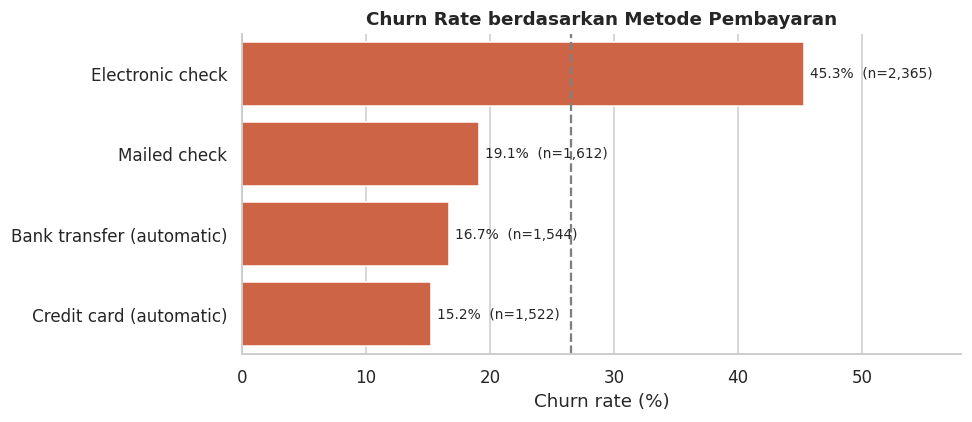

,PaymentMethod,churn_rate,n
2,Electronic check,45.3,2365
3,Mailed check,19.1,1612
0,Bank transfer (automatic),16.7,1544
1,Credit card (automatic),15.2,1522


In [15]:
t = churn_table('PaymentMethod').sort_values('churn_rate', ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=t, y='PaymentMethod', x='churn_rate', color=COL['Yes'], ax=ax)
for p, n in zip(ax.patches, t['n']):
    ax.text(p.get_width() + .5, p.get_y() + p.get_height()/2, f'{p.get_width():.1f}%  (n={n:,})', va='center', fontsize=9)
ax.axvline(overall*100, ls='--', c='grey'); ax.set_xlim(0, 58); ax.set_xlabel('Churn rate (%)'); ax.set_ylabel(''); ax.set_title('Churn Rate berdasarkan Metode Pembayaran')
plt.tight_layout(); plt.show()
t.round(1)

**Insight 6 — PaymentMethod**
- **Electronic check** churn **45,3%** (2.365 pelanggan), sedangkan pembayaran otomatis hanya **15–17%** (Credit card 15,2%, Bank transfer 16,7%); Mailed check 19,1%.
- Pembayaran otomatis menciptakan "gesekan" untuk berhenti dan mengurangi risiko lupa bayar; electronic check memerlukan aksi manual setiap bulan.
- **Implikasi bisnis:** dorong migrasi ke autopay (cashback, kemudahan). Electronic check berkorelasi dengan faktor lain (mis. kontrak bulanan, fiber), jadi efeknya sebagian tumpang tindih — bukan bukti sebab-akibat.

### Visualisasi 7 — Korelasi antarfitur numerik

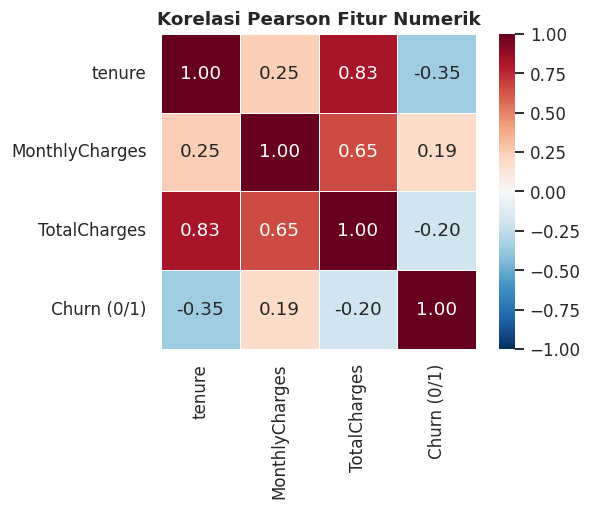

In [16]:
num = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'ChurnFlag']].rename(columns={'ChurnFlag': 'Churn (0/1)'})
corr = num.corr()
fig, ax = plt.subplots(figsize=(6, 4.8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True, linewidths=.5, ax=ax)
ax.set_title('Korelasi Pearson Fitur Numerik'); plt.tight_layout(); plt.show()

**Insight 7 — Korelasi numerik**
- `tenure` berkorelasi **negatif** dengan churn (**−0,35**): semakin lama berlangganan, semakin kecil kemungkinan churn.
- `MonthlyCharges` berkorelasi positif lemah (**+0,19**); `TotalCharges` negatif (**−0,20**) karena pada dasarnya mencerminkan tenure.
- **`tenure` dan `TotalCharges` sangat berkorelasi (0,83)** → multikolinearitas. Penting bagi model linear (koefisien tidak stabil) dan untuk interpretasi. `TotalCharges` ≈ tenure × MonthlyCharges sehingga informasinya sebagian redundan.
- Korelasi linear untuk target tidak besar; hubungan kategorikal (kontrak, layanan) tampak jauh lebih kuat, sehingga model non-linear berpotensi bermanfaat.

### Visualisasi 8 — Distribusi TotalCharges terhadap Churn

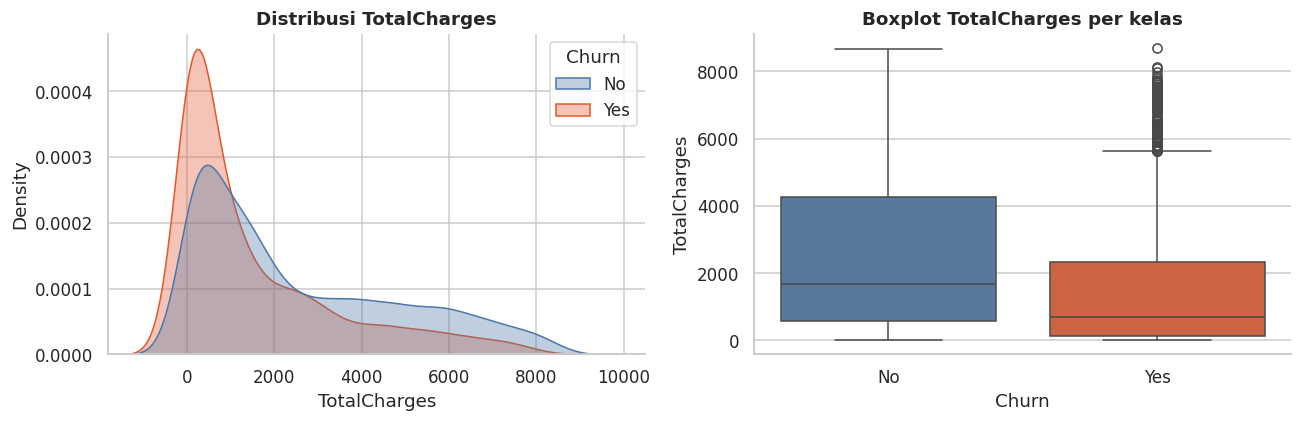

        count    mean     std   min    25%     50%     75%     max
Churn                                                             
No     5163.0  2555.3  2329.5  18.8  577.8  1683.6  4264.1  8672.4
Yes    1869.0  1531.8  1890.8  18.8  134.5   703.6  2331.3  8684.8


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(data=df.dropna(subset=['TotalCharges']), x='TotalCharges', hue='Churn', palette=COL, hue_order=['No', 'Yes'], common_norm=False, fill=True, alpha=.35, ax=ax[0])
ax[0].set_title('Distribusi TotalCharges')
sns.boxplot(data=df.dropna(subset=['TotalCharges']), x='Churn', y='TotalCharges', order=['No', 'Yes'], palette=COL, ax=ax[1])
ax[1].set_title('Boxplot TotalCharges per kelas')
plt.tight_layout(); plt.show()
print(df.groupby('Churn')['TotalCharges'].describe().round(1))

**Insight 8 — TotalCharges**
- Distribusi sangat **miring ke kanan**; median pelanggan churn hanya **703,6** vs **1.683,6** pelanggan bertahan.
- Pelanggan churn menumpuk pada `TotalCharges` rendah karena mereka cenderung churn dini (tenure pendek), bukan karena bayar sedikit per bulan — bahkan MonthlyCharges mereka lebih tinggi (Insight 4).
- **Implikasi bisnis:** pelanggan churn belum sempat "membayar kembali" biaya akuisisinya. Retensi dini lebih berharga. `TotalCharges` sebaiknya dipakai berhati-hati bersama `tenure` (kolinear).

### Analisis tambahan — Layanan pendukung dan demografi

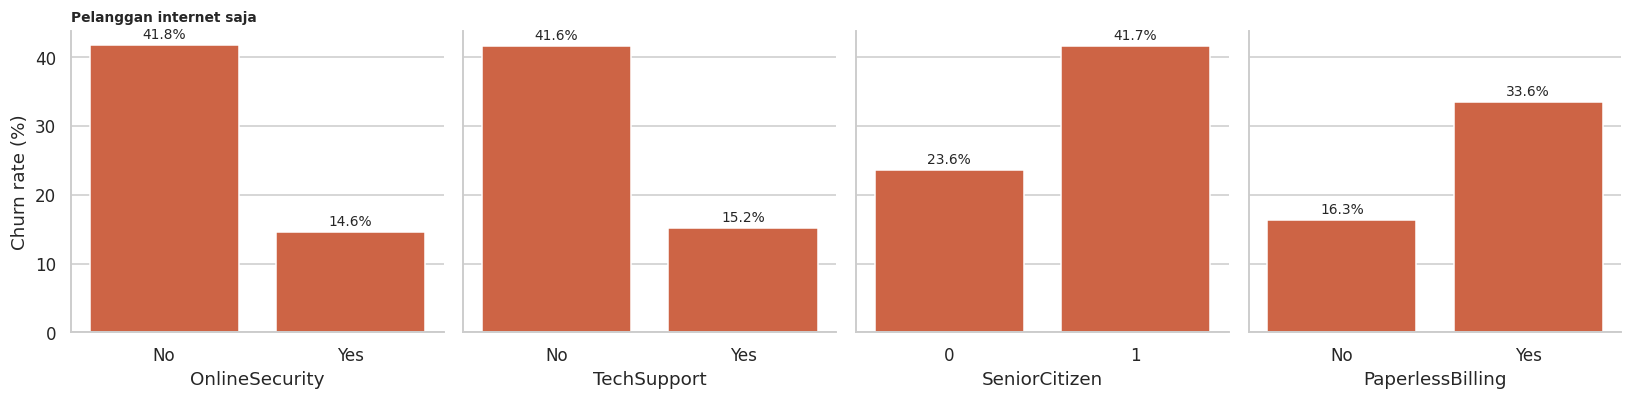

In [18]:
cols = ['OnlineSecurity', 'TechSupport', 'SeniorCitizen', 'PaperlessBilling']
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, c in zip(axes, cols):
    d = df if c in ('SeniorCitizen', 'PaperlessBilling') else df[df.InternetService != 'No']
    t = d.groupby(c)['ChurnFlag'].mean().mul(100).reset_index()
    sns.barplot(data=t, x=c, y='ChurnFlag', color=COL['Yes'], ax=ax); annotate_bars(ax); ax.set_ylabel('Churn rate (%)'); ax.set_xlabel(c)
axes[0].set_title('Pelanggan internet saja', fontsize=9, loc='left')
plt.tight_layout(); plt.show()

**Insight tambahan**
- Di antara pelanggan internet: yang **tanpa** OnlineSecurity churn sekitar 41,8% vs 14,6% yang memakai; **tanpa** TechSupport 41,6% vs 15,2% yang memakai.
- Senior citizen churn **41,7%** vs 23,6% non-senior; PaperlessBilling 33,6% vs 16,3%.
- Layanan pendukung berasosiasi dengan retensi lebih baik, namun pelanggan yang membeli add-on mungkin sudah lebih terikat (bias seleksi). Fitur `ServiceCount` pada Task 2 akan menangkap pola ini.

## Ringkasan Phase 1

| Aspek | Temuan utama |
|---|---|
| Kualitas data | Sangat baik: tanpa duplikat & outlier IQR; **satu masalah** → 11 baris `TotalCharges` kosong (pelanggan baru `tenure=0`) + tipe string. |
| Imbalance | 26,5% churn (1.869 dari 7.043) |
| Pendorong churn terkuat | Kontrak bulanan (42,7%), tenure ≤ 12 bulan (47,4%), fiber optic (41,9%), electronic check (45,3%), tanpa OnlineSecurity/TechSupport (~42%) |
| Catatan modeling | `tenure` ↔ `TotalCharges` korelasi 0,83 (multikolinear); butuh penanganan imbalance & threshold tuning; hindari akurasi sebagai metrik utama |

➡️ **Phase 2** akan membersihkan data, membuat fitur baru, membangun pipeline preprocessing, seleksi fitur, dan split 70/15/15.